# **About Dataset**

## **Context**
This Online Retail II data set contains all the transactions occurring for a UK-based and registered, non-store online retail between 01/12/2009 and 09/12/2011.The company mainly sells unique all-occasion gift-ware. Many customers of the company are wholesalers.

## **Content**
### **Attribute Information:**

**InvoiceNo:** Invoice number. Nominal. A 6-digit integral number uniquely assigned to each transaction. If this code starts with the letter 'c', it indicates a cancellation.

**StockCode:** Product (item) code. Nominal. A 5-digit integral number uniquely assigned to each distinct product.

**Description:** Product (item) name. Nominal.

**Quantity**: The quantities of each product (item) per transaction. Numeric.

**InvoiceDate:** Invice date and time. Numeric. The day and time when a transaction was generated.

**UnitPrice:** Unit price. Numeric. Product price per unit in sterling (Â£).

**CustomerID:** Customer number. Nominal. A 5-digit integral number uniquely assigned to each customer.

**Country:** Country name. Nominal. The name of the country where a customer resides.

#**1) Data Understanding**

In [28]:
# This code imports the pandas library as pd.
# It also imports the datetime library as dt and warnings library to filter warnings.
import pandas as pd
import datetime as dt
import warnings

# Visualization
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
import plotly.graph_objs as go
import plotly.offline as py

# Sets a filter to ignore warnings using the 'ignore' parameter.
warnings.filterwarnings('ignore')

# Configures some display options in the pandas library.
# Uses 'None' to show all columns and rows.
# Limits decimal numbers to three digits.
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

# **Dataset Loading**

In [29]:
df = pd.read_csv("/content/online_retail_II.csv")

In [30]:
# Creates a copy of the dataframe df_ and assigns it to the variable df.
df = df.copy()

# Displays the first 5 rows of the dataframe df.
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,13085.000,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085.000,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085.000,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,13085.000,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,13085.000,United Kingdom


In [31]:
# Displays general information about the dataframe df,
# including the data types, non-null counts, and memory usage.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB


In [32]:
# Define missing plot to detect all missing values in dataset
def missing_plot(dataset, key):
    null_feat = pd.DataFrame(len(dataset[key]) - dataset.isnull().sum(), columns=['Count'])
    percentage_null = pd.DataFrame((len(dataset[key]) - (len(dataset[key]) - dataset.isnull().sum())) / len(dataset[key]) * 100, columns=['Count'])
    percentage_null = percentage_null.round(2)

    trace = go.Bar(
        x=null_feat.index,
        y=null_feat['Count'],
        opacity=0.8,
        text=percentage_null['Count'],
        textposition='auto',
        marker=dict(
            color='#7EC0EE',  # Change the color of bars
            line=dict(
                color='#000000',
                width=1.5
            )
        ),
        width=0.5,  # Adjust the width of bars
    )

    layout = dict(title="Missing Values (count & %)", plot_bgcolor='rgba(0,0,0,0)',  # Set plot background color to transparent
                  xaxis=dict(title="Features"), yaxis=dict(title="Count"))

    fig = go.Figure(data=[trace], layout=layout)
    py.iplot(fig)

In [33]:
# Plotting
missing_plot(df, 'Invoice')

In [34]:
#How many different unique products ?
df["Description"].nunique()

5698

In [35]:
# Get the top 10 most preferred products
most_preferred_products = df['Description'].value_counts()[:10]

# Create the bar plot
fig = px.bar(x=most_preferred_products.index,
             y=most_preferred_products.values,
             color=most_preferred_products.index,
             text=most_preferred_products.values,
             title="Top 10 Most Preferred Products Per Shop",
             labels={'x': 'Product', 'y': 'Count'})

# Update layout for better appearance
fig.update_layout(
    xaxis_title="Product",
    yaxis_title="Count",
    font=dict(size=12, family="Arial"),
    title_font=dict(size=16, family="Arial")
)

# Show the plot
fig.show()

In [36]:
# Get the top 10 countries with the highest customer base
countries = df['Country'].value_counts()[:10]

# Create the bar plot
fig = px.bar(x=countries.index,
             y=countries.values,
             color=countries.index,
             text=countries.values,
             title="Customer Base by Countries",
             labels={'x': 'Country', 'y': 'Count'})

# Update layout for better appearance
fig.update_layout(
    xaxis_title="Country",
    yaxis_title="Count",
    font=dict(size=12, family="Arial"),
    title_font=dict(size=16, family="Arial")
)

# Show the plot
fig.show()


### **The graphs above illustrate that the majority of customers are from the UK compared to other countries.**

In [37]:
# Descending order of how many units of each product were purchased in total
df.groupby("Description").agg({"Quantity": "sum"}).sort_values("Quantity", ascending=False).head()

,Quantity
Description,
WORLD WAR 2 GLIDERS ASSTD DESIGNS,108545
WHITE HANGING HEART T-LIGHT HOLDER,93050
ASSORTED COLOUR BIRD ORNAMENT,81306
JUMBO BAG RED RETROSPOT,78090
BROCADE RING PURSE,70700


In [38]:
# How many invoices have been issued ?
df["Invoice"].nunique()

53628

In [39]:
# Calculate the total cost per invoice.
df["TotalPrice"] = df["Quantity"] * df["Price"]

In [40]:
# Descending order of how much was each invoice?
df.groupby("Invoice").agg({"TotalPrice": "sum"}).sort_values("TotalPrice", ascending=False).head()

,TotalPrice
Invoice,
581483,168469.600
541431,77183.600
574941,52940.940
576365,50653.910
533027,49844.990


### **2) Data Preparation**

In [41]:
# Delete rows without customer ID. Because we will make an analysis over customers.
# We also delete product information with empty rows under 1%.
# We aim to get healthy results in product-based analysis.
df.isnull().sum()

,0
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0
TotalPrice,0


In [42]:
df.dropna(inplace=True)

In [43]:
missing_plot(df, 'Customer ID')

In [44]:
df.shape

(824364, 9)

In [46]:
# Canceled invoices start with the letter C.
# The reason why the Quantity value is negative is that these refunded invoices are the sum of the refunded charges.
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Quantity,824364.000,12.415,188.976,-80995.000,2.000,5.000,12.000,80995.000
Price,824364.000,3.677,70.241,0.000,1.250,1.950,3.750,38970.000
Customer ID,824364.000,15324.639,1697.464,12346.000,13975.000,15255.000,16797.000,18287.000
TotalPrice,824364.000,20.195,308.685,-168469.600,4.250,11.250,19.500,168469.600


In [47]:
df['Invoice'] = df['Invoice'].astype(str)
df_refunded = df[df['Invoice'].str.contains('C')]

df_refunded.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.950,16321.000,Australia,-35.400
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.650,16321.000,Australia,-9.900
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.250,16321.000,Australia,-17.000
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.100,16321.000,Australia,-12.600
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.950,16321.000,Australia,-35.400


In [49]:
# There are 9839 refunded records
df_refunded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18744 entries, 178 to 1067178
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Invoice      18744 non-null  object 
 1   StockCode    18744 non-null  object 
 2   Description  18744 non-null  object 
 3   Quantity     18744 non-null  int64  
 4   InvoiceDate  18744 non-null  object 
 5   Price        18744 non-null  float64
 6   Customer ID  18744 non-null  float64
 7   Country      18744 non-null  object 
 8   TotalPrice   18744 non-null  float64
dtypes: float64(3), int64(1), object(5)
memory usage: 1.9+ MB


In [50]:
# We continue by removing the refunded records.
df = df[~df["Invoice"].str.contains("C", na = False)]
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 805620 entries, 0 to 1067370
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      805620 non-null  object 
 1   StockCode    805620 non-null  object 
 2   Description  805620 non-null  object 
 3   Quantity     805620 non-null  int64  
 4   InvoiceDate  805620 non-null  object 
 5   Price        805620 non-null  float64
 6   Customer ID  805620 non-null  float64
 7   Country      805620 non-null  object 
 8   TotalPrice   805620 non-null  float64
dtypes: float64(3), int64(1), object(5)
memory usage: 61.5+ MB


In [51]:
# Check the total records
df.shape[0] + df_refunded.shape[0]

824364

In [52]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Quantity,805620.000,13.308,144.307,1.000,2.000,5.000,12.000,80995.000
Price,805620.000,3.206,29.198,0.000,1.250,1.950,3.750,10953.500
Customer ID,805620.000,15331.856,1696.768,12346.000,13982.000,15271.000,16805.000,18287.000
TotalPrice,805620.000,22.025,224.032,0.000,4.950,11.850,19.500,168469.600


In [53]:
# Analyze the products with a sale price of 0 and remove these records as well.
# Boolean indexing
df_ZeroPrice = df[df['Price'] == 0]
df_ZeroPrice.shape

(71, 9)

In [54]:
df_ZeroPrice.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
4674,489825,22076,6 RIBBONS EMPIRE,12,2009-12-02 13:34:00,0.000,16126.000,United Kingdom,0.000
6781,489998,48185,DOOR MAT FAIRY CAKE,2,2009-12-03 11:19:00,0.000,15658.000,United Kingdom,0.000
16107,490727,M,Manual,1,2009-12-07 16:38:00,0.000,17231.000,United Kingdom,0.000
18738,490961,22065,CHRISTMAS PUDDING TRINKET POT,1,2009-12-08 15:25:00,0.000,14108.000,United Kingdom,0.000
18739,490961,22142,CHRISTMAS CRAFT WHITE FAIRY,12,2009-12-08 15:25:00,0.000,14108.000,United Kingdom,0.000


In [55]:
df.drop(df[df['Price'] == 0.0].index, inplace=True)

In [56]:
# After 31 deleted records, there should be 407664 records.
df.shape

(805549, 9)

In [57]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,13085.000,United Kingdom,83.400
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085.000,United Kingdom,81.000
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085.000,United Kingdom,81.000
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,13085.000,United Kingdom,100.800
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,13085.000,United Kingdom,30.000


# **3) Extract meaningful insights**

In [58]:
# date, month, week, time
# Convert 'InvoiceDate' column to datetime format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Create 'date', 'month', 'week', and 'time' columns
df['date'] = df['InvoiceDate'].dt.strftime('%m/%d/%Y')
df['month'] = df['InvoiceDate'].dt.strftime('%B')
df['week'] = df['InvoiceDate'].dt.strftime('%A')
df['time'] = df['InvoiceDate'].dt.strftime('%H')

In [59]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice,date,month,week,time
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,13085.000,United Kingdom,83.400,12/01/2009,December,Tuesday,07
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085.000,United Kingdom,81.000,12/01/2009,December,Tuesday,07
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085.000,United Kingdom,81.000,12/01/2009,December,Tuesday,07
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,13085.000,United Kingdom,100.800,12/01/2009,December,Tuesday,07
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,13085.000,United Kingdom,30.000,12/01/2009,December,Tuesday,07


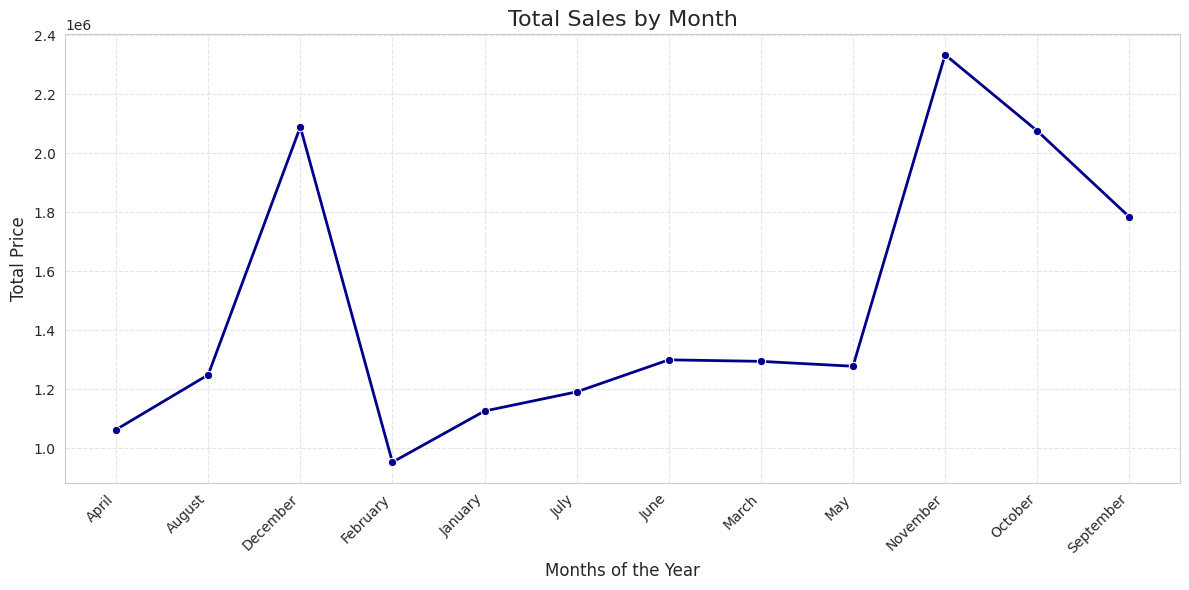

In [60]:
# Calculate the total sales by month
df_months = df.groupby('month').agg({'TotalPrice': 'sum'}).reset_index()

# Set the style
sns.set_style("whitegrid")

# Plot the line plot
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_months, x='month', y='TotalPrice', marker='o', color='darkblue', linewidth=2)
plt.title('Total Sales by Month', fontsize=16)
plt.xlabel('Months of the Year', fontsize=12)
plt.ylabel('Total Price', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)  # Add grid lines
plt.tight_layout()
plt.show()

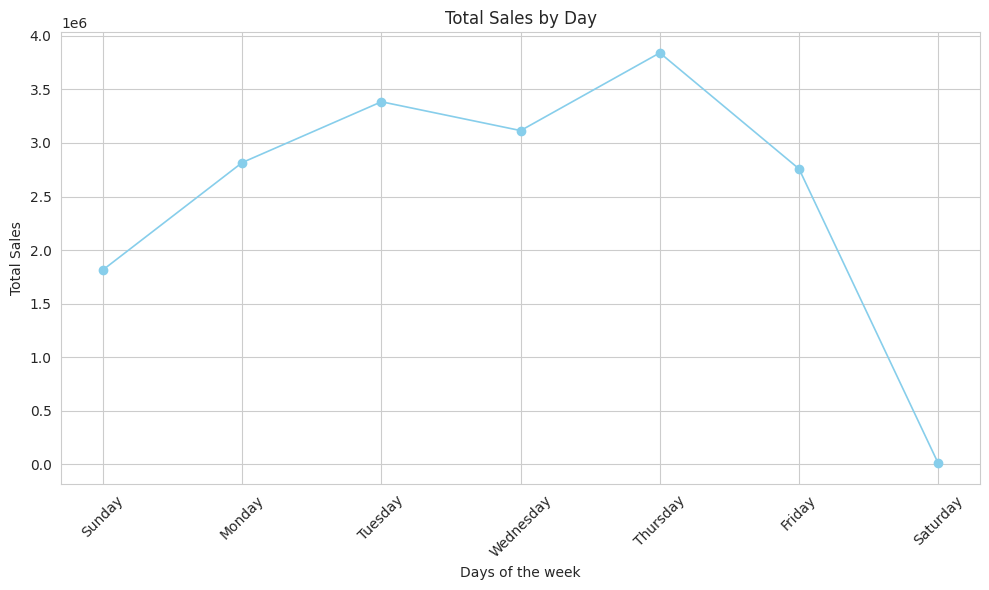

In [61]:
import pandas as pd
import matplotlib.pyplot as plt

# Assume 'data' is your DataFrame containing 'week' and 'Total_sales' columns

# Calculating total sales on a daily basis
daywise = df.groupby('week').agg({'TotalPrice': 'sum'}).reset_index()

# Reordering the table according to weekdays
daywise['week'] = pd.Categorical(daywise['week'], categories=["Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"], ordered=True)
daywise = daywise.sort_values('week')

# Line plot
plt.figure(figsize=(10, 6))
plt.plot(daywise['week'], daywise['TotalPrice'], marker='o', color='skyblue', linewidth=1.2, markersize=6)
plt.title('Total Sales by Day')
plt.xlabel('Days of the week')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

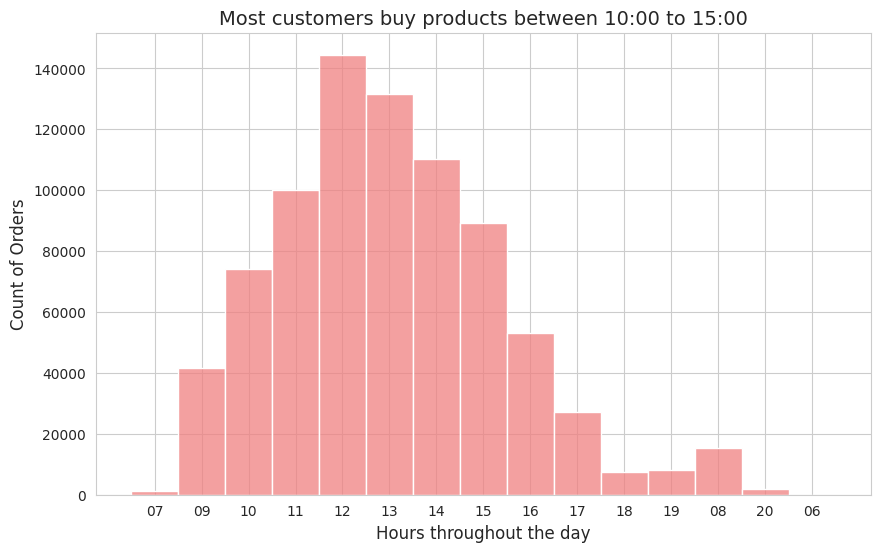

In [62]:
# Set the style
sns.set_style("whitegrid")

# Plotting the histogram
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='time', bins=24, color='lightcoral', kde=False)
plt.xlabel('Hours throughout the day', fontsize=12)
plt.ylabel('Count of Orders', fontsize=12)
plt.title('Most customers buy products between 10:00 to 15:00', fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.grid(True)
plt.show()

# **During data preparation**
Columns with missing values were identified. These records were deleted for user-based analysis.


Canceled invoices(C374759) were found and removed for the health of the analysis.


Records with a product sales price of 0.000 were deleted from the data set.